# Prepare a working directory

# Train the model

In [ ]:
from ultralytics import YOLO

# pretrained model
model = YOLO('yolo12x.pt')

# train the model
results = model.train(
    data='./datasets/child_vs_adult/data.yaml',
    epochs=500,
    imgsz=640,
    batch=-1,
    workers=10,
    patience=40,
    plots=True,
    cache='disk',
    project='Intellgi',
    name='child_recog'
)

In [1]:
from ultralytics import YOLO

# pretrained model
model = YOLO('./Intellgi/child_recog/weights/last.pt')

# train the model
results = model.train(
    resume=True
)

New https://pypi.org/project/ultralytics/8.3.229 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.228 🚀 Python-3.13.9 torch-2.9.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24575MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=6, bgr=0.0, box=7.5, cache=disk, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./datasets/child_vs_adult/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=500, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=Intellgi/child_recog/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=Fa

# Validate model on test data

In [1]:
from ultralytics import YOLO

model = YOLO('./Intellgi/child_recog/weights/best.pt')

metrices = model.val(
    data='./datasets/child_vs_adult/data.yaml',
    workers=20,
    plots=True,
    save_json=True,
    project='Intellgi',
    name='child_recog',
    conf=0.7,
    split='test',
    batch=16
)

Ultralytics 8.3.228 🚀 Python-3.13.9 torch-2.9.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24575MiB)
YOLOv12x summary (fused): 283 layers, 59,045,654 parameters, 0 gradients, 198.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 138.6±38.8 MB/s, size: 58.9 KB)
val: Scanning /home/labuser/Joy/IntellgiCare/datasets/child_vs_adult/test/labels... 620 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 620/620 200.8it/s 3.1s0.1s
val: New cache created: /home/labuser/Joy/IntellgiCare/datasets/child_vs_adult/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 39/39 2.3it/s 16.9s0.4s
                   all        620       4834      0.963      0.931      0.956      0.853
                 Adult        574       1041      0.964      0.943      0.962      0.879
                 Child        587       3793      0.962      0.918       0.95      0.828
Speed: 1.6ms preprocess, 18.2ms inference, 0.0ms loss, 1.3ms postproces

## Inferencing the model

In [1]:
from ultralytics import YOLO

# Load the model
model = YOLO('/home/labuser/Joy/IntellgiCare/Intellgi/child_recog/weights/best.pt')


image 1/1 /home/labuser/Joy/IntellgiCare/test/images/daycare_image_1.jpg: 448x640 3 Childs, 251.5ms
Speed: 6.2ms preprocess, 251.5ms inference, 27.0ms postprocess per image at shape (1, 3, 448, 640)


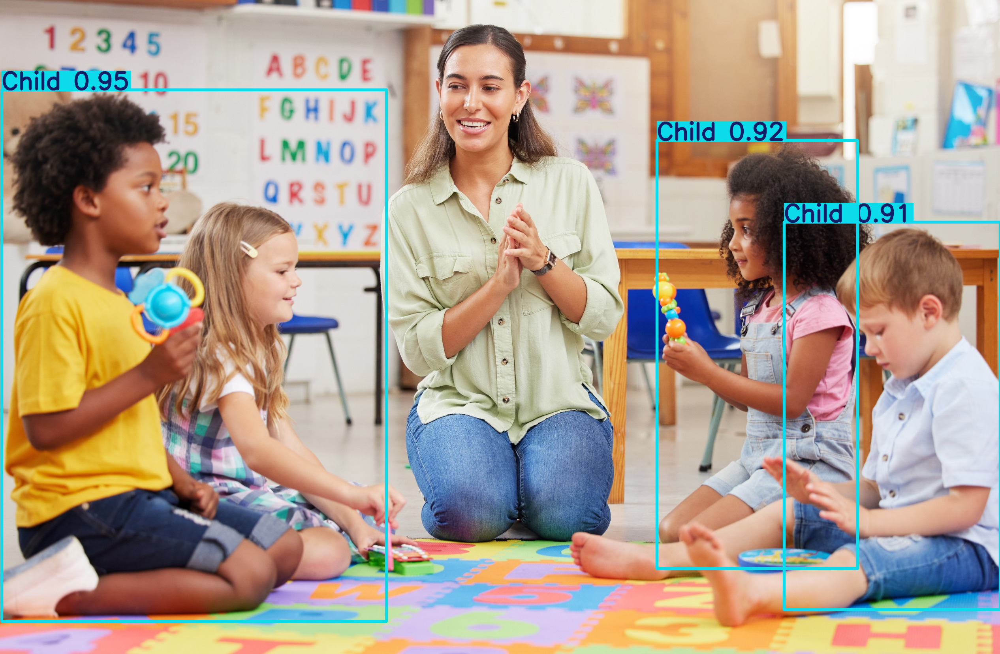

In [12]:
image_path = './test/images/daycare_image_1.jpg'
results = model.predict(image_path, save=False, conf=0.75, classes=[1])
results[0].show()

In [13]:
results[0].boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1., 1., 1.], device='cuda:0')
conf: tensor([0.9450, 0.9199, 0.9103], device='cuda:0')
data: tensor([[4.5520e+00, 2.2729e+02, 9.7825e+02, 1.5735e+03, 9.4501e-01, 1.0000e+00],
        [1.6637e+03, 3.5521e+02, 2.1719e+03, 1.4396e+03, 9.1991e-01, 1.0000e+00],
        [1.9852e+03, 5.6251e+02, 2.5320e+03, 1.5430e+03, 9.1031e-01, 1.0000e+00]], device='cuda:0')
id: None
is_track: False
orig_shape: (1656, 2532)
shape: torch.Size([3, 6])
xywh: tensor([[ 491.4016,  900.3928,  973.6994, 1346.2069],
        [1917.7981,  897.4228,  508.2274, 1084.4354],
        [2258.6228, 1052.7642,  546.7543,  980.5023]], device='cuda:0')
xywhn: tensor([[0.1941, 0.5437, 0.3846, 0.8129],
        [0.7574, 0.5419, 0.2007, 0.6549],
        [0.8920, 0.6357, 0.2159, 0.5921]], device='cuda:0')
xyxy: tensor([[   4.5520,  227.2893,  978.2513, 1573.4962],
        [1663.6844,  355.2050, 2171.9119, 1439.6405],
        [1985.2457,  562.5129, 2532.0000, 1543

#### Track

In [1]:
from ultralytics import YOLO

model = YOLO('/home/labuser/Joy/IntellgiCare/Intellgi/child_recog/weights/best.pt')


image 1/1 /home/labuser/Joy/IntellgiCare/test/images/daycare_image_1.jpg: 448x640 3 Childs, 285.5ms
Speed: 3.6ms preprocess, 285.5ms inference, 2.7ms postprocess per image at shape (1, 3, 448, 640)


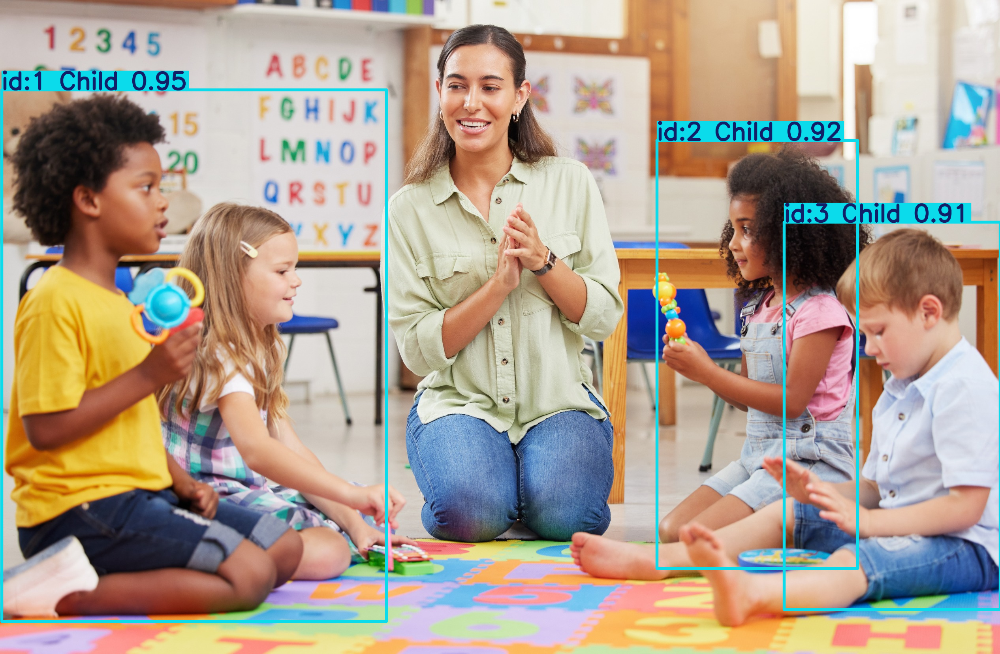

In [18]:
image_path = './test/images/daycare_image_1.jpg'
results = model.track(
    image_path,
    tracker='botsort.yaml',
    conf=0.8,
    save=False,
    imgsz=640,
    classes=[1]
)[0]
results.show()

In [19]:
results.boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([1., 1., 1.])
conf: tensor([0.9450, 0.9199, 0.9103])
data: tensor([[4.5519e+00, 2.2729e+02, 9.7825e+02, 1.5735e+03, 1.0000e+00, 9.4501e-01, 1.0000e+00],
        [1.6637e+03, 3.5521e+02, 2.1719e+03, 1.4396e+03, 2.0000e+00, 9.1991e-01, 1.0000e+00],
        [1.9852e+03, 5.6251e+02, 2.5320e+03, 1.5430e+03, 3.0000e+00, 9.1031e-01, 1.0000e+00]])
id: tensor([1., 2., 3.])
is_track: True
orig_shape: (1656, 2532)
shape: torch.Size([3, 7])
xywh: tensor([[ 491.4016,  900.3928,  973.6994, 1346.2069],
        [1917.7980,  897.4228,  508.2273, 1084.4354],
        [2258.6228, 1052.7642,  546.7544,  980.5024]])
xywhn: tensor([[0.1941, 0.5437, 0.3846, 0.8129],
        [0.7574, 0.5419, 0.2007, 0.6549],
        [0.8920, 0.6357, 0.2159, 0.5921]])
xyxy: tensor([[   4.5519,  227.2893,  978.2513, 1573.4962],
        [1663.6843,  355.2051, 2171.9116, 1439.6405],
        [1985.2456,  562.5130, 2532.0000, 1543.0154]])
xyxyn: tensor([[0.0018, 0

In [20]:
results.boxes.cpu().xyxy.numpy()

array([[     4.5519,      227.29,      978.25,      1573.5],
       [     1663.7,      355.21,      2171.9,      1439.6],
       [     1985.2,      562.51,        2532,        1543]], dtype=float32)

In [29]:
boxes = results.boxes.cpu()
detections = []
if boxes.is_track:
    ids = boxes.id.numpy()
    cls = boxes.cls.numpy()
    confs = boxes.conf.numpy()
    xyxys = boxes.xyxy.numpy()

    for id, cl, conf, xyxy in zip(ids, cls, confs, xyxys):
        detections.append([id.item(), int(cl), conf.item(), xyxy.tolist()])

detections

[[1.0,
  1,
  0.9450135231018066,
  [4.55194091796875, 227.289306640625, 978.2513427734375, 1573.4962158203125]],
 [2.0,
  1,
  0.9199054837226868,
  [1663.684326171875, 355.205078125, 2171.91162109375, 1439.6405029296875]],
 [3.0,
  1,
  0.9103140830993652,
  [1985.24560546875, 562.5130004882812, 2532.0, 1543.015380859375]]]